<a href="https://colab.research.google.com/github/dkalchenko01/Final-project-Time-Series/blob/main/02_daylight_ensemble.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Second submission: Daylight ensemble

This notebook continues from the first submission, ETS Box–Cox 30d + seasonal naive. It reconstructs the steps leading to the scored Daylight ensemble: a direct MLP, averaging two seeds, and adding daylight features.

The final forecast gives 25% weight to ETS, 25% to seasonal naive, and 25% to each of two daylight MLPs. The original interval recipe is kept. Later SARIMA experiments, residual corrections, and public-score-based interval changes are outside this notebook.

Every fit uses only observations before its forecast origin. The historical windows were reused during development, so these results are retrospective, not an untouched final test.

## 1. Setup and data

In [1]:
%pip install -q statsforecast==2.1.1 scikit-learn

In [3]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import boxcox
from scipy.special import inv_boxcox
from statsforecast.models import AutoETS
warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.figsize": (11, 3), "axes.grid": True, "grid.alpha": .25})

DATA_DIR = Path("data")
if not (DATA_DIR / "train.csv").exists():
    DATA_DIR = Path(".")  # Colab: upload both CSV files.
data = pd.read_csv(DATA_DIR / "train.csv", parse_dates=["ds"])
weather_fc = pd.read_csv(DATA_DIR / "weather_forecast.csv", parse_dates=["ds"])
y = data["y"].to_numpy(float)
H, M = 48, 24
FUTURE = weather_fc["ds"].reset_index(drop=True)
assert data.ds.is_monotonic_increasing and data.ds.is_unique
assert data.ds.diff().dropna().eq(pd.Timedelta(hours=1)).all()
assert np.isfinite(data.drop(columns="ds").to_numpy()).all() and (y > 0).all()
assert FUTURE.equals(pd.Series(pd.date_range(data.ds.iloc[-1]+pd.Timedelta(hours=1), periods=H, freq="h"), name="ds"))
print("History:", data.ds.iloc[0], "to", data.ds.iloc[-1])

from sklearn.neural_network import MLPRegressor
from sklearn.compose import TransformedTargetRegressor
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler


print("Forecast:", FUTURE.iloc[0], "to", FUTURE.iloc[-1])
display(data.tail())

History: 2023-01-01 01:00:00 to 2026-10-27 00:00:00
Forecast: 2026-10-27 01:00:00 to 2026-10-29 00:00:00


,ds,y,cloud_cover,temperature,wind_speed,pressure,humidity,daylight,air_density
33475,2026-10-26 20:00:00,42.5,1.0,9,3,763,87,0,1.258851
33476,2026-10-26 21:00:00,76.7,1.0,9,4,763,87,0,1.258851
33477,2026-10-26 22:00:00,65.8,1.0,7,3,763,100,0,1.267842
33478,2026-10-26 23:00:00,69.9,1.0,7,3,763,100,0,1.267842
33479,2026-10-27 00:00:00,69.9,1.0,7,3,763,100,0,1.267842


## 2. Starting point

The first notebook found a strong daily cycle, changing recent levels and remaining short-lag dependence. Its 30-day ETS + naive combination improved point accuracy, but could produce wide intervals on quiet periods.

I keep that model as the reference. All comparisons below use the same dates, horizon and interval-calibration procedure. No new EDA is needed here.

### Other candidates explored

| Candidate | Result and decision |
|---|---|
| Ridge + first model | Improved recent results, but gains were small on the older period. Kept as an alternative. |
| Boosting | Some promising point forecasts, but intervals needed substantial calibration. |
| Prophet | The tested settings did not beat the first model on RMSE. |
| Direct MLP | More useful in combination with the first model than alone. Continued with seed averaging and daylight features. |
| STL + ETS / ARIMAX | The tested settings did not improve the early comparisons. Weather tests used repeated-day inputs, which limits the conclusion. |
| NeuralForecast MLP / N-BEATS | Limited by runtime; the short runs were insufficient to judge these models reliably. |

These were exploratory comparisons on different historical periods, not a single final ranking.

In [4]:
def snaive(history, h=H, m=M):
    history = np.asarray(history, float)
    point = np.resize(history[-m:], h)
    sigma = np.std(history[m:] - history[:-m], ddof=1)
    half = 1.96 * sigma * np.sqrt(1 + np.arange(h)//m)
    return point, np.maximum(point-half, 0), point+half

def ets_naive(history):
    z, lam = boxcox(history["y"].tail(30*M).to_numpy(float))
    model = AutoETS(season_length=M, model="AAA", damped=True).fit(y=z)
    fc = model.predict(h=H, level=[95])
    point = inv_boxcox(fc["mean"], lam)
    if lam > 0:
        lower = np.maximum(1+lam*fc["lo-95"], 0)**(1/lam)
    else:
        lower = inv_boxcox(fc["lo-95"], lam)
    upper = inv_boxcox(fc["hi-95"], lam)
    ets = (point, lower, upper)
    naive = snaive(history["y"].to_numpy(float))
    return tuple((a+b)/2 for a,b in zip(ets, naive))

def calibrate(prediction, past_predictions):
    point, lower, upper = [a.copy() for a in prediction]
    scale = np.maximum((upper-lower)/2, 1)
    for part in [slice(0,24), slice(24,48)]:
        errors = []
        for end, (_, lo, hi) in past_predictions.items():
            actual = y[end:end+H]
            miss = np.maximum.reduce([lo-actual, actual-hi, np.zeros(H)])
            errors.extend((miss/np.maximum((hi-lo)/2, 1))[part])
        errors = np.sort(errors)
        rank = int(np.ceil((len(errors)+1)*.95))
        q = errors[rank-1]
        lower[part] = np.maximum(lower[part]-q*scale[part], 0)
        upper[part] += q*scale[part]
    return point, lower, upper

In [5]:
def score(actual, prediction):
    point, lower, upper = prediction
    return {"RMSE": np.sqrt(np.mean((actual-point)**2)),
            "MAPE": 100*np.mean(np.abs(actual-point)/actual),
            "Winkler": np.mean(upper-lower+40*np.maximum(lower-actual,0)+40*np.maximum(actual-upper,0)),
            "coverage": np.mean((actual>=lower)&(actual<=upper)),
            "width": np.mean(upper-lower)}

PARTS = {"all": slice(None), "day 2": slice(24,48)}

def mix(*predictions):
    return tuple(np.mean([p[i] for p in predictions], axis=0) for i in range(3))

def evaluate(predictions, origins, warmup=8):
    rows = []
    for name, forecasts in predictions.items():
        for i, end in enumerate(origins):
            if i < warmup:
                continue
            if name == "seasonal naive":
                prediction = forecasts[end]
            else:
                previous = {o: forecasts[o] for o in origins[max(0,i-12):i]}
                prediction = calibrate(forecasts[end], previous)
            for part, index in PARTS.items():
                rows.append({"model":name, "origin":end, "part":part,
                             **score(y[end:end+H][index], tuple(a[index] for a in prediction))})
    return pd.DataFrame(rows)

def summarize(scores, part="day 2"):
    group = scores[scores.part == part].groupby("model")
    table = group[["MAPE", "Winkler", "coverage", "width"]].mean()
    table["mean window RMSE"] = group.RMSE.mean()
    table["pooled RMSE"] = group.RMSE.agg(lambda x: np.sqrt(np.mean(x*x)))
    return table.sort_values("pooled RMSE")


## 3. Direct MLP

The MLP learns from the last 90 days. It uses the previous week of generation, recent averages and variability, the hour of day and a weekend flag to predict the next 48 hours at once.

I use Box–Cox and standardize the inputs and targets. The network has two hidden layers (64 and 32 neurons), regularization `alpha=1` and at most 100 training iterations.

The daylight version also uses day/night indicators. For the next 48 hours, I repeat the last observed day's indicators twice.

In [6]:
def transform_target(values, kind="raw"):
    values = np.asarray(values, float)
    if kind == "raw":
        return values.copy(), None
    if not (values > 0).all():
        raise ValueError("Positive values required")
    if kind == "log":
        return np.log(values), None
    if kind == "boxcox":
        return boxcox(values)
    raise ValueError("Use raw, log or boxcox")

def inverse_target(values, kind="raw", lam=None):
    values = np.asarray(values, float)
    if kind == "raw":
        return values.copy()
    if kind == "log":
        return np.exp(values)
    if kind == "boxcox":
        return inv_boxcox(values, lam)
    raise ValueError("Use raw, log or boxcox")

def search_features(dates, hour_dummies=False):
    dates = pd.DatetimeIndex(dates)
    hour = dates.hour.to_numpy()
    if hour_dummies:
        x = [(hour == k).astype(float) for k in range(1, 24)]
    else:
        x = [fun(2 * np.pi * k * hour / 24)
             for k in range(1, 6) for fun in [np.sin, np.cos]]
    x.append((dates.dayofweek >= 5).astype(float))
    return np.column_stack(x)

def direct_input(z, dates, origin, context, h):
    past = z[origin - context:origin]
    future_dates = dates[origin:origin + h]
    # History, recent level/variability, and genuinely known future calendar.
    features = np.r_[past,
        [np.mean(past[-w:]) for w in [24, 72, 168]],
        [np.std(past[-w:]) for w in [24, 72, 168]],
        search_features(future_dates).ravel()]
    return features

def daylight_mlp_input(z, dates, daylight, origin, context, h, use_daylight=True):
    original = direct_input(z, dates, origin, context, h)

    if not use_daylight:
        return original
    past_light = daylight[origin - context:origin]

    # Train-only approximation of future daylight.
    future_light = np.resize(daylight[origin - M:origin], h)

    return np.r_[original, past_light, future_light]

def daylight_mlp_forecast(history, cfg, h=48):
    train = history.tail(cfg["days"] * M).reset_index(drop=True)

    assert train["daylight"].isin([0, 1]).all()

    z, lam = transform_target(train["y"], cfg["scale"])
    dates = pd.DatetimeIndex(train["ds"])
    daylight = train["daylight"].to_numpy(float)
    context = cfg["context"]

    cutoffs = np.arange(context, len(z) - h + 1, 6)

    x = np.array([
        daylight_mlp_input(
            z, dates, daylight, origin, context, h, cfg["use_daylight"]
        )
        for origin in cutoffs
    ])

    target = np.array([
        z[origin:origin + h]
        for origin in cutoffs
    ])

    # Keep the same network settings for every comparison.
    regressor = MLPRegressor(
        hidden_layer_sizes=tuple(cfg["hidden"]),
        alpha=1.0,
        max_iter=cfg["iterations"],
        early_stopping=False,
        shuffle=False,
        random_state=cfg["seed"],
    )

    model = TransformedTargetRegressor(
        regressor=make_pipeline(StandardScaler(), regressor),
        transformer=StandardScaler(),
    )
    model.fit(x, target)

    future_dates = pd.date_range(
        dates[-1] + pd.Timedelta(hours=1),
        periods=h,
        freq="h",
    )

    row = daylight_mlp_input(
        z,
        dates.append(future_dates),
        daylight,
        len(z),
        context,
        h,
        cfg["use_daylight"],
    )

    pred = model.predict(row[None, :])[0]
    point = np.maximum(
        inverse_target(pred, cfg["scale"], lam), 0
    )

    if not np.isfinite(point).all():
        raise ValueError("Invalid inverse transformation")

    # Heuristic component bounds; the ensemble is calibrated later.
    values = train["y"].to_numpy(float)
    sigma = np.std(values[M:] - values[:-M], ddof=1)
    half = 1.96 * sigma * np.sqrt(1 + np.arange(h) // M)

    return point, np.maximum(point - half, 0), point + half

In [7]:
def mlp_forecast(history, seed=1, use_daylight=False):
    cfg = {"days":90, "scale":"boxcox", "context":168,
           "hidden":[64,32], "iterations":100, "seed":seed,
           "use_daylight":use_daylight}
    return daylight_mlp_forecast(history, cfg, H)


## 4. Comparing models and combinations

I make 28 historical forecasts of 48 hours each. The first 8 collect errors for interval calibration; the next 20 are scored. Intervals are adjusted using up to 12 earlier forecasts. Seasonal naive keeps its original intervals.

I compare:
- The first model (ETS + seasonal naive).
- MLP alone.
- The first model mixed 50/50 with an MLP, using seed 1 or 2.
- The same combination with both seeds averaged.
- The two-seed combination with daylight features.

For each combination, I average the forecasts and bounds, then calibrate the bounds using past errors.

In [8]:
ORIGINS = [len(data)-k*H for k in range(28,0,-1)]
NAMES = ["seasonal naive", "First combo 30d", "MLP alone",
         "Combo + MLP seed 1", "Combo + MLP seed 2",
         "Original MLP ensemble", "Daylight MLP ensemble"]
predictions = {name:{} for name in NAMES}
for i, end in enumerate(ORIGINS):
    history = data.iloc[:end]
    baseline = ets_naive(history)
    mlp1 = mlp_forecast(history, seed=1)
    mlp2 = mlp_forecast(history, seed=2)
    light1 = mlp_forecast(history, seed=1, use_daylight=True)
    light2 = mlp_forecast(history, seed=2, use_daylight=True)
    predictions["seasonal naive"][end] = snaive(y[:end])
    predictions["First combo 30d"][end] = baseline
    predictions["MLP alone"][end] = mix(mlp1, mlp2)
    predictions["Combo + MLP seed 1"][end] = mix(baseline, mlp1)
    predictions["Combo + MLP seed 2"][end] = mix(baseline, mlp2)
    predictions["Original MLP ensemble"][end] = mix(baseline, mix(mlp1, mlp2))
    predictions["Daylight MLP ensemble"][end] = mix(baseline, mix(light1, light2))
    print(i+1, "of", len(ORIGINS), "completed", flush=True)
scores = evaluate(predictions, ORIGINS)
for part in PARTS:
    print(part)
    display(summarize(scores, part))


1 of 28 completed
2 of 28 completed
3 of 28 completed
4 of 28 completed
5 of 28 completed
6 of 28 completed
7 of 28 completed
8 of 28 completed
9 of 28 completed
10 of 28 completed
11 of 28 completed
12 of 28 completed
13 of 28 completed
14 of 28 completed
15 of 28 completed
16 of 28 completed
17 of 28 completed
18 of 28 completed
19 of 28 completed
20 of 28 completed
21 of 28 completed
22 of 28 completed
23 of 28 completed
24 of 28 completed
25 of 28 completed
26 of 28 completed
27 of 28 completed
28 of 28 completed
all


,MAPE,Winkler,coverage,width,mean window RMSE,pooled RMSE
model,,,,,,
First combo 30d,226.735041,1307.860395,0.950000,1094.920446,274.929980,292.315749
Daylight MLP ensemble,224.377700,1273.945582,0.957292,1023.594915,282.073906,293.620653
Original MLP ensemble,228.517561,1286.803706,0.951042,1025.076541,284.362070,296.947269
Combo + MLP seed 1,219.464022,1283.793513,0.948958,1036.948976,286.219986,298.937017
Combo + MLP seed 2,238.611129,1325.331547,0.944792,1036.366835,291.498904,303.139082
seasonal naive,249.000623,2396.704958,0.748958,671.364126,308.922150,322.015649
MLP alone,235.748643,1579.092812,0.955208,1254.052456,330.174406,347.324247


day 2


,MAPE,Winkler,coverage,width,mean window RMSE,pooled RMSE
model,,,,,,
Daylight MLP ensemble,150.405081,1244.109103,0.960417,1070.196661,284.558625,298.815176
Original MLP ensemble,153.994683,1254.539133,0.956250,1071.402596,288.090434,304.526995
Combo + MLP seed 1,151.128382,1240.117901,0.956250,1074.811752,290.610750,306.646823
First combo 30d,155.301781,1401.586376,0.947917,1094.341208,280.688566,306.921491
Combo + MLP seed 2,157.686977,1296.761896,0.947917,1073.116003,293.981836,310.072519
seasonal naive,187.639142,2095.179520,0.822917,775.401814,313.939888,334.310321
MLP alone,158.324007,1545.565763,0.960417,1210.444821,331.859668,352.170567


### Reading the comparison

The MLP alone has worse RMSE than the first ETS+snaive model. However, combining them improves the second-day forecast, so the MLP is more useful as part of the ensemble than on its own.

The two seeds give different results, even with the same network settings. I average their forecasts instead of choosing the seed that happened to perform better on these windows.

Adding daylight improves the two-seed ensemble on day 2: pooled RMSE falls from 305 to 299, MAPE from 154 to 150, and Winkler from 1255 to 1244. The daylight features give the network information about the difference between daytime and night-time hours.

Compared with the first model, the daylight ensemble also has better second-day RMSE (299 vs 307) and Winkler (1244 vs 1402). Its intervals cover about 96% of observations, close to the 95% target.

The improvement does not hold everywhere. Across all 48 hours, pooled RMSE is slightly worse than the first ETS+snaive model (294 vs 292), although Winkler is better (1274 vs 1308). I therefore check the models on an older period before making the final choice.

## 5. Checking another period

I test the same models on earlier dates without changing their settings. Each forecast still uses only the preceding 30 days for ETS and 90 days for the MLP.

This checks whether the results also hold outside the recent period. These dates were inspected during development, so this is not an untouched test.

In [9]:
OLDER_ORIGINS = [min(ORIGINS)-k*H for k in range(20,0,-1)]
older_predictions = {name:{} for name in ["seasonal naive", "First combo 30d",
                                         "Original MLP ensemble", "Daylight MLP ensemble"]}
for i, end in enumerate(OLDER_ORIGINS):
    history = data.iloc[:end]
    baseline = ets_naive(history)
    original = mix(mlp_forecast(history,1), mlp_forecast(history,2))
    daylight = mix(mlp_forecast(history,1,True), mlp_forecast(history,2,True))
    older_predictions["seasonal naive"][end] = snaive(y[:end])
    older_predictions["First combo 30d"][end] = baseline
    older_predictions["Original MLP ensemble"][end] = mix(baseline,original)
    older_predictions["Daylight MLP ensemble"][end] = mix(baseline,daylight)
    print(i+1, "of", len(OLDER_ORIGINS), "completed", flush=True)
older_scores = evaluate(older_predictions, OLDER_ORIGINS)
for part in PARTS:
    print(part)
    display(summarize(older_scores, part))


1 of 20 completed
2 of 20 completed
3 of 20 completed
4 of 20 completed
5 of 20 completed
6 of 20 completed
7 of 20 completed
8 of 20 completed
9 of 20 completed
10 of 20 completed
11 of 20 completed
12 of 20 completed
13 of 20 completed
14 of 20 completed
15 of 20 completed
16 of 20 completed
17 of 20 completed
18 of 20 completed
19 of 20 completed
20 of 20 completed
all


,MAPE,Winkler,coverage,width,mean window RMSE,pooled RMSE
model,,,,,,
Original MLP ensemble,50.299104,979.998179,0.979167,941.328083,188.220955,200.112938
Daylight MLP ensemble,49.074202,978.364235,0.977431,935.335878,192.049713,204.219207
First combo 30d,54.123087,1241.720759,0.954861,1103.763616,194.130170,205.984774
seasonal naive,57.893937,1035.116732,0.909722,679.697603,193.179943,209.198961


day 2


,MAPE,Winkler,coverage,width,mean window RMSE,pooled RMSE
model,,,,,,
Original MLP ensemble,52.154721,1046.179630,0.986111,1038.194577,187.164433,204.131745
Daylight MLP ensemble,51.198872,1040.077778,0.986111,1032.092725,190.274425,206.591627
First combo 30d,59.560624,1146.473848,0.951389,1016.047353,193.819803,211.712738
seasonal naive,65.225883,1151.087684,0.940972,786.609946,213.367908,235.346249


### Results on the older period

The daylight ensemble also improves on the first model here. On day 2, pooled RMSE falls from 212 to 207, MAPE from 59.6 to 51.2 and Winkler from 1146 to 1040.

Adding daylight does not improve everything. The ensemble without daylight has slightly better RMSE (204 vs 207), while daylight gives slightly better MAPE and Winkler. Both cover about 98.6% of observations, suggesting conservative intervals.

I keep the daylight ensemble because it performs well across both periods, especially on day 2. The differences are small, so this is a practical choice rather than a clear win on every metric.

### Additional checks

I also tested a smaller MLP input set. RMSE improved slightly, but MAPE increased and recent Winkler became worse, so I kept the original features.

The day/night analysis motivated adding daylight indicators. Night-time errors can strongly affect MAPE, while overpredicted daytime peaks can strongly affect RMSE. Daylight helped some comparisons but did not remove the shared peak errors.

## 6. Inspecting a difficult forecast

Compare the two-seed ensembles against the first model on the window where the original ensemble worsens second-day RMSE most. This is a diagnostic plot, not a new tuning target.

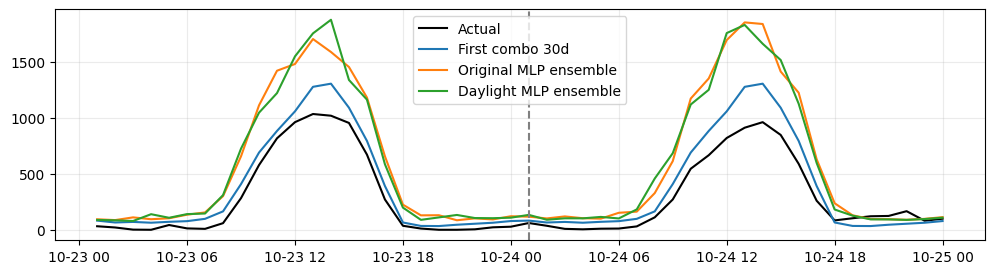

Forecast start: 2026-10-23 01:00:00


In [10]:
comparison = scores[scores.part == "day 2"].pivot(index="origin", columns="model", values="RMSE")
worst = (comparison["Original MLP ensemble"]-comparison["First combo 30d"]).idxmax()
fig, ax = plt.subplots(figsize=(12,3))
ax.plot(data.ds.iloc[worst:worst+H], y[worst:worst+H], color="black", label="Actual")
for name in ["First combo 30d", "Original MLP ensemble", "Daylight MLP ensemble"]:
    ax.plot(data.ds.iloc[worst:worst+H], predictions[name][worst][0], label=name)
ax.axvline(data.ds.iloc[worst+24], color="grey", linestyle="--")
ax.legend(); plt.show()
print("Forecast start:", data.ds.iloc[worst])


The neural ensembles can overpredict a day's peak together. Averaging seeds does not protect against the same structural error in both networks. This is a remaining limitation of the submitted recipe; the plot is not used to impose a hand-tuned peak cap.

## 7. Final submitted model

The forecast is 25% ETS Box–Cox 30d + 25% seasonal naive + 25% daylight MLP seed 1 + 25% daylight MLP seed 2. Each MLP uses 90 days and a 168-hour input context.

I average component bounds, then widen them using the last 12 completed 48-hour forecast errors. This is the same calibration as in the first notebook. It can widen but cannot shrink bounds; it may be conservative on a quiet day. No published scores enter the model.

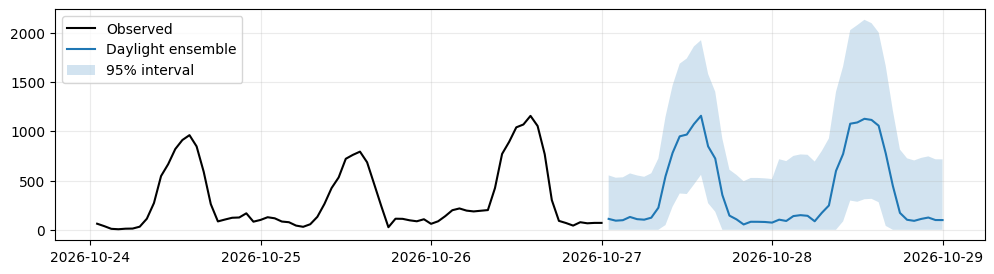

Mean widths, day 1 / day 2: 815.2502947880913 1079.814543029838


In [11]:
baseline = ets_naive(data)
light1 = mlp_forecast(data, seed=1, use_daylight=True)
light2 = mlp_forecast(data, seed=2, use_daylight=True)
raw_final = mix(baseline, mix(light1,light2))
previous = {o:predictions["Daylight MLP ensemble"][o] for o in ORIGINS[-12:]}
point, lower, upper = calibrate(raw_final, previous)
fig, ax = plt.subplots(figsize=(12,3))
ax.plot(data.ds.tail(72), y[-72:], color="black", label="Observed")
ax.plot(FUTURE, point, label="Daylight ensemble")
ax.fill_between(FUTURE, lower, upper, alpha=.2, label="95% interval")
ax.legend(); plt.show()
print("Mean widths, day 1 / day 2:", np.mean((upper-lower)[:24]), np.mean((upper-lower)[24:]))


## 8. Export

Write the reproduced forecast. The archived scored file is not overwritten. If the archive is available, compare it with the reproduced values.

In [12]:
submission = pd.DataFrame({"ds":FUTURE, "forecast":point,
                           "lower_95":lower, "upper_95":upper})
assert submission.shape == (H,4)
assert np.isfinite(submission.iloc[:,1:].to_numpy()).all()
assert (lower>=0).all() and (lower<=point).all() and (point<=upper).all()
output = Path("submissions")
output.mkdir(exist_ok=True)
submission.to_csv(output / "daylight_ensemble_reproduced.csv", index=False)
archive = output / "daylight_ensemble.csv"
if archive.exists():
    archived = pd.read_csv(archive)
    assert pd.to_datetime(archived.ds).equals(FUTURE)
    difference = np.max(np.abs(submission.iloc[:,1:].to_numpy()-archived.iloc[:,1:].to_numpy()))
    print("Largest difference from the archived submission:", difference)
else:
    print("Archive not found; comparison skipped.")
print("Format OK")


Archive not found; comparison skipped.
Format OK
